# Nº 08 · La descente de gradient

*θ Théta, le Machine Learning, une notion à la fois.*

Ce notebook refait les calculs de l'épisode, avec du Python simple :

1. écrire la règle θ ← θ − η∇J(θ) ;
2. vérifier les trois pas faits à la main ;
3. comparer trois taux d'apprentissage ;
4. voir pourquoi une pente nulle ne veut pas dire un coût nul.

Chaque résultat est vérifié par un `assert` : si un calcul s'écarte de l'épisode, le notebook s'arrête.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. La règle, en quelques lignes

On prend le coût le plus simple, J(θ) = θ², dont la pente vaut 2θ (épisode 06).
Un pas consiste à retrancher à θ la pente multipliée par le taux d'apprentissage η.

In [2]:
def cout(theta):
    return theta**2


def pente(theta):
    return 2 * theta


def descendre(theta0, eta, pas):
    """Renvoie θ après chaque pas, en commençant par θ0."""
    thetas = [theta0]
    for _ in range(pas):
        thetas.append(thetas[-1] - eta * pente(thetas[-1]))
    return np.array(thetas)

## 2. Trois pas, à la main

Avec θ = 3 et η = 0,1, l'épisode donne 2,4, puis 1,92, puis 1,536.

In [3]:
thetas = descendre(3, 0.1, 3)
for t, theta in enumerate(thetas):
    print(f"itération {t} : θ = {theta:.3f}, J = {cout(theta):.3f}, pente = {pente(theta):.3f}")

assert np.allclose(thetas, [3, 2.4, 1.92, 1.536])

itération 0 : θ = 3.000, J = 9.000, pente = 6.000
itération 1 : θ = 2.400, J = 5.760, pente = 4.800
itération 2 : θ = 1.920, J = 3.686, pente = 3.840
itération 3 : θ = 1.536, J = 2.359, pente = 3.072


Les pas raccourcissent d'eux-mêmes alors que η ne change pas : le pas vaut η × la pente, et la pente diminue
près du minimum.

In [4]:
pas_effectues = -np.diff(thetas)
print("taille des pas :", np.round(pas_effectues, 3))
assert (np.diff(pas_effectues) < 0).all()

taille des pas : [0.6   0.48  0.384]


## 3. Le bon pas : ni trop petit, ni trop grand

Même courbe, même départ, trois valeurs de η, comme sur la page Comparaison de l'épisode.

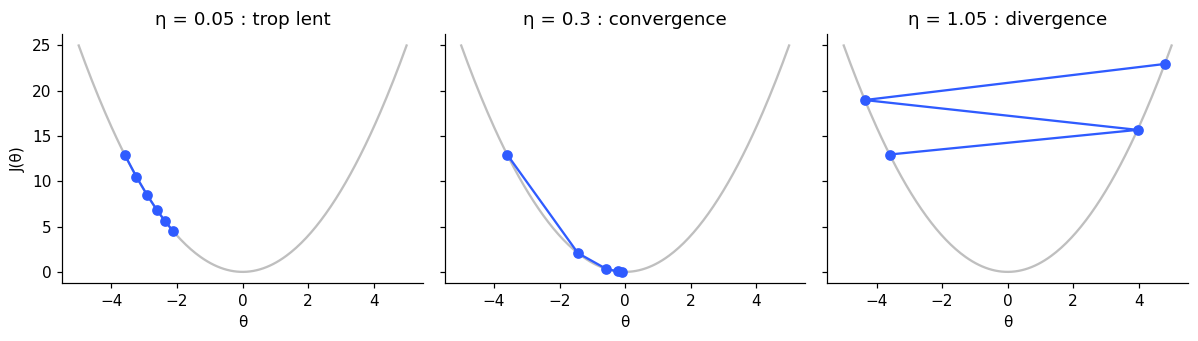

In [5]:
cas = [(0.05, 5, "trop lent"), (0.3, 4, "convergence"), (1.05, 3, "divergence")]
grille = np.linspace(-5, 5, 200)

figure, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for axe, (eta, pas, nom) in zip(axes, cas):
    chemin = descendre(-3.6, eta, pas)
    axe.plot(grille, cout(grille), color="0.75")
    axe.plot(chemin, cout(chemin), "o-", color="#2F5BFF")
    axe.set_title(f"η = {eta} : {nom}")
    axe.set_xlabel("θ")
axes[0].set_ylabel("J(θ)")
plt.tight_layout()

In [6]:
assert abs(descendre(-3.6, 0.05, 5)[-1]) > 2  # encore loin du minimum après 5 pas
assert abs(descendre(-3.6, 0.3, 4)[-1]) < 0.1  # tout près du minimum après 4 pas
assert abs(descendre(-3.6, 1.05, 3)[-1]) > 3.6  # s'éloigne à chaque pas

Sur J(θ) = θ², chaque pas multiplie θ par (1 − 2η). Cela explique les trois comportements :
la descente converge si ce facteur a une valeur absolue inférieure à 1, soit 0 < η < 1, et diverge au-delà.

In [7]:
for eta in (0.05, 0.3, 1.05):
    print(f"η = {eta} : facteur {1 - 2 * eta:+.2f}")
assert abs(1 - 2 * 1.05) > 1 > abs(1 - 2 * 0.3)

η = 0.05 : facteur +0.90
η = 0.3 : facteur +0.40
η = 1.05 : facteur -1.10


## 4. Pente nulle ne veut pas dire coût nul

Ajoutons une constante au coût : J(θ) = θ² + 2. Le minimum reste en θ = 0, où la pente est nulle.
La descente s'y arrête, mais le coût vaut encore 2. Il faudrait un autre modèle pour faire mieux.

In [8]:
fin = descendre(3, 0.3, 40)[-1]
print(f"θ = {fin:.6f}, pente = {pente(fin):.6f}, coût = {cout(fin) + 2:.6f}")
assert abs(pente(fin)) < 1e-6 and abs(cout(fin) + 2 - 2) < 1e-6

θ = 0.000000, pente = 0.000000, coût = 2.000000


## À vous

1. Avec η = 1 exactement, que fait θ ? Prévoyez le résultat, puis vérifiez.
2. Remplacez J(θ) = θ² par J(θ) = 3θ². Quel η provoque maintenant la divergence ?

**Sources** : Cauchy (1847), Ruder (2016), Machine Learning Crash Course. Les références complètes figurent dans
le premier commentaire de l'épisode.